# Titanic: do dado bruto à submissão

**Autor:** Vinicius Brum  
**Competição:** [Titanic — Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic) (Kaggle)

Este notebook percorre o fluxo completo de uma competição de classificação tabular:

1. explorar os passageiros do Titanic e entender quem tinha mais chance de sobreviver;
2. criar atributos (título, família, convés, tarifa por pessoa, interação classe × sexo e o truque de `FamilySurvival`) sem vazar informação da validação ou do teste;
3. comparar modelos regularizados com validação cruzada estratificada de 10 folds, repetida 3 vezes, e montar um ensemble de votação suave;
4. treinar o modelo escolhido no conjunto completo e gerar `submissions/submission.csv`.

A métrica oficial da competição é a **acurácia**: a porcentagem de previsões corretas de sobrevivência (`0` ou `1`) nos 418 passageiros do teste oculto.

> **Nota honesta sobre o ranking.** O topo da leaderboard pública tem centenas de notas de 100%. Isso só acontece porque a lista completa de quem sobreviveu no teste é pública na internet — não porque alguém treinou um modelo perfeito. As melhores soluções **legítimas** giram em torno de **80–82%** no ranking público. Esta solução não usa rótulos vazados.


## 1. Configuração e leitura dos dados

Os arquivos `train.csv` (891 passageiros, com o alvo `Survived`) e `test.csv` (418 passageiros, sem o alvo) devem estar em `data/`. O download oficial está em [kaggle.com/competitions/titanic/data](https://www.kaggle.com/competitions/titanic/data).

O pré-processamento reutilizável vive em `src/features.py` (`TitanicFeatureEngineer` + `ColumnTransformer`). O treino e a validação cruzada repetida vivem em `src/train.py`.


In [1]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Garante que o notebook funcione tanto a partir da raiz do repositório
# quanto de dentro de notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.features import TitanicFeatureEngineer, build_preprocessor, extract_title
from src.train import (
    RANDOM_STATE,
    N_REPEATS,
    N_SPLITS,
    build_passenger_pool,
    collect_top_features,
    evaluate_models,
    fit_best_and_predict,
    load_data,
    pick_best,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 110,
})

# Paleta: verde-azulado = sobreviveu, terracota = não sobreviveu.
COR_SURV = "#2A9D8F"
COR_DIED = "#E76F51"
COR_ACCENT = "#264653"

DATA_DIR = ROOT / "data"
SUBMISSION_PATH = ROOT / "submissions" / "submission.csv"

X, y, test = load_data(DATA_DIR)
pool = build_passenger_pool(X, test)
train = X.copy()
train["Survived"] = y

print(f"Raiz do projeto: {ROOT}")
print(f"Treino: {train.shape[0]} linhas, {train.shape[1]} colunas")
print(f"Teste:  {test.shape[0]} linhas, {test.shape[1]} colunas")
print("Colunas do treino:", list(train.columns))
print("Colunas do teste: ", list(test.columns))
assert len(train) == 891, "O treino oficial tem 891 passageiros."
assert len(test) == 418, "O teste oficial tem 418 passageiros."
assert list(train.columns) == [
    "PassengerId", "Pclass", "Name", "Sex", "Age", "SibSp",
    "Parch", "Ticket", "Fare", "Cabin", "Embarked", "Survived",
]
assert list(test.columns) == [
    "PassengerId", "Pclass", "Name", "Sex", "Age", "SibSp",
    "Parch", "Ticket", "Fare", "Cabin", "Embarked",
]
train.head()


Raiz do projeto: /workspace/kaggle-titanic
Treino: 891 linhas, 12 colunas
Teste:  418 linhas, 11 colunas
Colunas do treino: ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Survived']
Colunas do teste:  ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0


## 2. Análise exploratória

Antes de modelar, vale entender o desbalanceamento do alvo e as relações mais fortes com a sobrevivência. No treino, **cerca de 38%** dos passageiros sobreviveram — um pouco abaixo de metade, então um modelo que chute sempre “não sobreviveu” já acertaria ~62%.


In [2]:
print("Taxa de sobrevivência no treino: "
      f"{train['Survived'].mean():.1%} ({int(y.sum())} de {len(y)})")
print("\nValores ausentes no treino:")
missing = (
    train.isna().sum()
    .rename("n_ausentes")
    .to_frame()
    .assign(pct=lambda d: (d["n_ausentes"] / len(train) * 100).round(1))
)
missing = missing[missing["n_ausentes"] > 0].sort_values("n_ausentes", ascending=False)
display(missing)

print("Valores ausentes no teste:")
missing_test = (
    test.isna().sum()
    .rename("n_ausentes")
    .to_frame()
    .assign(pct=lambda d: (d["n_ausentes"] / len(test) * 100).round(1))
)
display(missing_test[missing_test["n_ausentes"] > 0])


Taxa de sobrevivência no treino: 38.4% (342 de 891)

Valores ausentes no treino:


,n_ausentes,pct
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


Valores ausentes no teste:


,n_ausentes,pct
Age,86,20.6
Fare,1,0.2
Cabin,327,78.2


Há **177 idades ausentes** no treino (20%) e 86 no teste; a cabine está ausente na maior parte dos casos (687 e 327). No teste falta **uma tarifa**, e no treino faltam **dois portos de embarque**. Esses buracos precisam ser imputados com estatísticas aprendidas só no fold de treino.


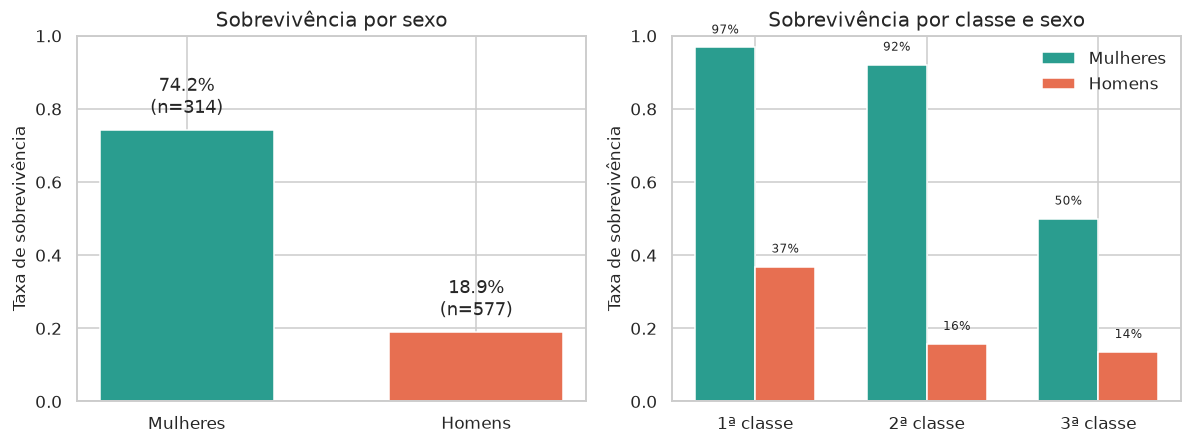

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

sexo = (
    train.groupby("Sex")["Survived"]
    .agg(taxa="mean", n="count")
    .reindex(["female", "male"])
)
axes[0].bar(
    ["Mulheres", "Homens"],
    sexo["taxa"],
    color=[COR_SURV, COR_DIED],
    width=0.6,
)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Taxa de sobrevivência")
axes[0].set_title("Sobrevivência por sexo")
for i, (taxa, n) in enumerate(zip(sexo["taxa"], sexo["n"])):
    axes[0].text(i, taxa + 0.03, f"{taxa:.1%}\n(n={n})", ha="center", va="bottom")

classe_sexo = (
    train.groupby(["Pclass", "Sex"])["Survived"]
    .mean()
    .unstack()
    .reindex(columns=["female", "male"])
)
x = np.arange(3)
w = 0.35
axes[1].bar(x - w / 2, classe_sexo["female"], width=w, label="Mulheres", color=COR_SURV)
axes[1].bar(x + w / 2, classe_sexo["male"], width=w, label="Homens", color=COR_DIED)
axes[1].set_xticks(x)
axes[1].set_xticklabels(["1ª classe", "2ª classe", "3ª classe"])
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Taxa de sobrevivência")
axes[1].set_title("Sobrevivência por classe e sexo")
axes[1].legend(frameon=False)
for i, pclass in enumerate([1, 2, 3]):
    for j, sex in enumerate(["female", "male"]):
        taxa = classe_sexo.loc[pclass, sex]
        xpos = x[i] + (-w / 2 if j == 0 else w / 2)
        axes[1].text(xpos, taxa + 0.03, f"{taxa:.0%}", ha="center", va="bottom", fontsize=8)

fig.tight_layout()
plt.show()


**Leitura.** O sexo e a classe dominam o problema — o famoso “mulheres e crianças primeiro”, filtrado pelo acesso aos botes:

- mulheres sobreviveram a **74,2%**, homens a apenas **18,9%**;
- mulheres da 1ª e da 2ª classe: **96,8%** e **92,1%**;
- homens da 3ª classe, o maior grupo (347 pessoas): apenas **13,5%**.

Qualquer modelo razoável precisa capturar essa interação. Ainda assim, há sinal extra em idade, família e título, como vemos a seguir.


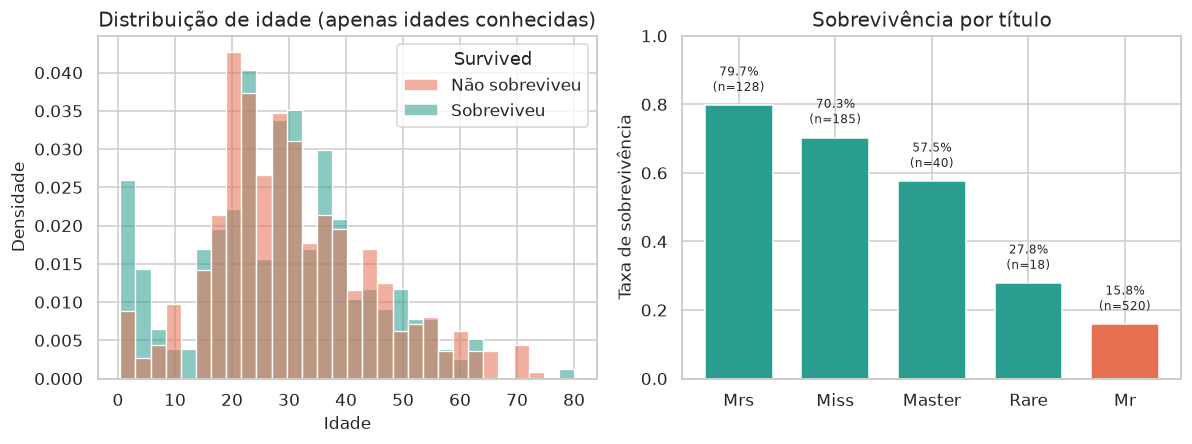

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

idade = train.dropna(subset=["Age"])
sns.histplot(
    data=idade,
    x="Age",
    hue="Survived",
    bins=30,
    stat="density",
    common_norm=False,
    palette={0: COR_DIED, 1: COR_SURV},
    alpha=0.55,
    ax=axes[0],
)
axes[0].set_title("Distribuição de idade (apenas idades conhecidas)")
axes[0].set_xlabel("Idade")
axes[0].set_ylabel("Densidade")
leg = axes[0].get_legend()
if leg is not None:
    for text, label in zip(leg.get_texts(), ["Não sobreviveu", "Sobreviveu"]):
        text.set_text(label)

train = train.copy()
train["Title"] = train["Name"].map(extract_title)
titulo = (
    train.groupby("Title")["Survived"]
    .agg(taxa="mean", n="count")
    .reindex(["Mrs", "Miss", "Master", "Rare", "Mr"])
)
cores_titulo = [COR_SURV if t != "Mr" else COR_DIED for t in titulo.index]
axes[1].bar(titulo.index, titulo["taxa"], color=cores_titulo, width=0.7)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Taxa de sobrevivência")
axes[1].set_title("Sobrevivência por título")
for i, (taxa, n) in enumerate(zip(titulo["taxa"], titulo["n"])):
    axes[1].text(i, taxa + 0.03, f"{taxa:.1%}\n(n={int(n)})", ha="center", va="bottom", fontsize=8)

fig.tight_layout()
plt.show()


**Leitura.** O título não é só um proxy de sexo: **Master** (meninos) sobreviveu a **57,5%**, contra **15,7%** dos **Mr**. A mediana de idade de Master é **3,5 anos**, a de Mr é **30**. Por isso a imputação de idade é feita **por título**, e não por uma mediana global — completar a idade de uma criança com 28 anos distorceria o sinal.


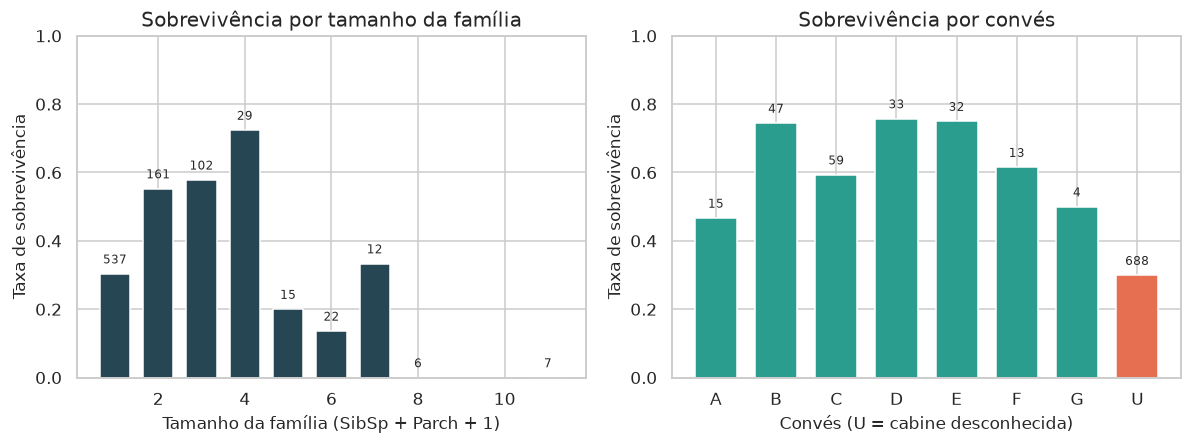

In [5]:
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1
train["Deck"] = train["Cabin"].fillna("U").astype(str).str[0].replace({"T": "U"})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

fam = train.groupby("FamilySize")["Survived"].agg(taxa="mean", n="count")
axes[0].bar(fam.index, fam["taxa"], color=COR_ACCENT, width=0.7)
axes[0].set_xlabel("Tamanho da família (SibSp + Parch + 1)")
axes[0].set_ylabel("Taxa de sobrevivência")
axes[0].set_title("Sobrevivência por tamanho da família")
axes[0].set_ylim(0, 1)
for i, row in fam.iterrows():
    axes[0].text(i, row["taxa"] + 0.03, str(int(row["n"])), ha="center", fontsize=8)

deck = train.groupby("Deck")["Survived"].agg(taxa="mean", n="count").sort_index()
cores = [COR_DIED if d == "U" else COR_SURV for d in deck.index]
axes[1].bar(deck.index, deck["taxa"], color=cores, width=0.7)
axes[1].set_xlabel("Convés (U = cabine desconhecida)")
axes[1].set_ylabel("Taxa de sobrevivência")
axes[1].set_title("Sobrevivência por convés")
axes[1].set_ylim(0, 1)
for i, (idx, row) in enumerate(deck.iterrows()):
    axes[1].text(i, row["taxa"] + 0.03, str(int(row["n"])), ha="center", fontsize=8)

fig.tight_layout()
plt.show()


**Leitura.** Famílias **pequenas ou médias** (2 a 4 pessoas) sobreviveram bem mais (55%–72%) do que quem viajava **sozinho** (30%) ou em **famílias muito grandes** (0%–20% acima de 4). Ter a cabine registrada também é informativo: nos conveses B, D e E a sobrevivência passa de **74%**, enquanto a maioria sem cabine (`U`, 687 passageiros) fica em **30%**. Isso mistura classe social e o simples fato de o registro da cabine ter sido preservado, mas ainda é um atributo útil (`HasCabin` + `Deck`).


## 3. Engenharia de atributos

O transformador `TitanicFeatureEngineer` aprende no `fit` (apenas no fold de treino) e aplica no `transform`:

| Atributo | Como é criado |
| --- | --- |
| `Title` | Título do nome, normalizado para `Mr`, `Mrs`, `Miss`, `Master` ou `Rare` |
| `FamilySize` e `IsAlone` | `SibSp + Parch + 1`; indicador de quem viajava sozinho |
| `Age` | Imputada pela **mediana do título**; fallback para a mediana global |
| `Fare` | Imputada pela mediana da **classe** (`Pclass`) |
| `FareBin` | Faixas em quantis cujos cortes vêm do treino |
| `FarePerPerson` | `Fare / FamilySize` |
| `Deck` e `HasCabin` | Primeira letra da cabine, ou `U` se ausente |
| `Embarked` | Imputado pela moda do treino (na prática, `S`) |
| `PclassSex` | Interação explícita de classe e sexo (ex.: `1_female`) |
| `FamilySurvival` | Sobrevivência do grupo familiar ou do ticket (veja a seção 3.1) |
| `GroupSize` | Tamanho do grupo (união família ∪ ticket) em treino + teste, sem usar o alvo |

Em seguida um `ColumnTransformer` padroniza as variáveis numéricas e aplica *one-hot* nas categóricas. Assim, regressão logística, SVC, KNN e árvores recebem a mesma matriz.


### 3.1 O truque do `FamilySurvival` (sem vazamento)

Famílias e grupos que compraram o mesmo ticket tendem a viver ou morrer juntos. Esse é o sinal extra mais conhecido nas soluções **legítimas** que passam de 80% na leaderboard pública.

O cálculo, implementado em `src/features.py`, segue o truque clássico, com dois cuidados para não vazar o alvo:

1. **Como o grupo é formado.** Primeiro tentamos o par *sobrenome + tarifa*. Se aquele passageiro ainda não tem companheiros rotulados, usamos quem compartilha o mesmo *ticket* (ama, amigos, passageiros no mesmo recibo). Sem companheiros rotulados, o valor fica em **0,5**.
2. **Leave-one-out e isolamento do fold.** Os rótulos vêm só do `fit`. Para uma linha do próprio treino, a sobrevivência **dela** é retirada da conta: se a família inteira sobreviveu, cada membro vê `1` por causa dos *outros*; se viajava sozinho, vê `0,5`, nunca o próprio rótulo. Na validação cruzada isso é refeito em cada fold, então um passageiro da validação só enxerga rótulos do fold de treino. O teste de verdade usa todos os 891 rótulos oficiais — e nenhum rótulo externo.

`GroupSize` pode olhar treino e teste juntos, porque a composição do grupo é um atributo visível (ticket, nome, tarifa), não o alvo.

O gráfico abaixo mostra o `FamilySurvival` calculado em leave-one-out no treino completo, só para ilustrar o sinal. Na CV o cálculo é ainda mais conservador (só o fold de treino).


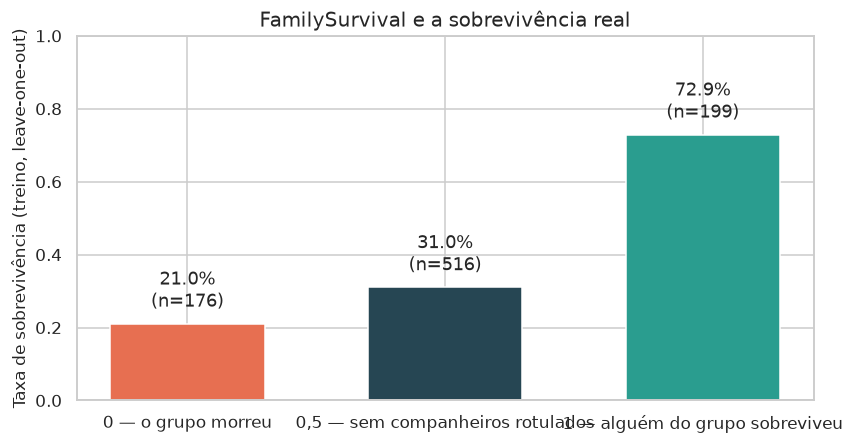

Tamanho do grupo (treino): média 2.19, máximo 11


In [6]:
engineer = TitanicFeatureEngineer(passenger_pool=pool).fit(X, y)
feat_train = engineer.transform(X)
feat_train["Survived"] = y.values

fig, ax = plt.subplots(figsize=(8, 4.2))
ordem = [0.0, 0.5, 1.0]
rotulos = {
    0.0: "0 — o grupo morreu",
    0.5: "0,5 — sem companheiros rotulados",
    1.0: "1 — alguém do grupo sobreviveu",
}
grupo = (
    feat_train.groupby("FamilySurvival")["Survived"]
    .agg(taxa="mean", n="count")
    .reindex(ordem)
)
cores = [COR_DIED, COR_ACCENT, COR_SURV]
ax.bar([rotulos[v] for v in ordem], grupo["taxa"], color=cores, width=0.6)
ax.set_ylim(0, 1)
ax.set_ylabel("Taxa de sobrevivência (treino, leave-one-out)")
ax.set_title("FamilySurvival e a sobrevivência real")
for i, v in enumerate(ordem):
    ax.text(
        i,
        grupo.loc[v, "taxa"] + 0.03,
        f"{grupo.loc[v, 'taxa']:.1%}\n(n={int(grupo.loc[v, 'n'])})",
        ha="center",
        va="bottom",
    )
fig.tight_layout()
plt.show()

print(
    "Tamanho do grupo (treino): "
    f"média {feat_train['GroupSize'].mean():.2f}, "
    f"máximo {int(feat_train['GroupSize'].max())}"
)


**Leitura.** Quem tem companheiros rotulados que sobreviveram (`FamilySurvival = 1`) se salva em torno de **73%**; quem tem companheiros que morreram, em torno de **21%**; quem não tem grupo informativo fica perto da média geral (**31%**). É um sinal forte, mas só é honesto se for calculado em leave-one-out — do contrário o modelo “olharia” a própria resposta.


In [7]:
exemplo = engineer.transform(X.head(8))[
    [
        "Name", "Title", "Age", "FamilySize", "PclassSex",
        "FarePerPerson", "FareBin", "Deck", "FamilySurvival", "GroupSize",
    ]
]
display(exemplo)

prep = build_preprocessor(passenger_pool=pool)
Xt = prep.fit_transform(X, y)
nomes = prep.named_steps["preprocess"].get_feature_names_out()
print(f"Matriz após o pipeline: {Xt.shape[0]} × {Xt.shape[1]} atributos")
print("Atributos:", list(nomes))


,Name,Title,Age,FamilySize,PclassSex,FarePerPerson,FareBin,Deck,FamilySurvival,GroupSize
0,"Braund, Mr. Owen Harris",Mr,22.0,2,3_male,3.62500,Q1,U,0.5,1
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,38.0,2,1_female,35.64165,Q4,C,0.5,2
2,"Heikkinen, Miss. Laina",Miss,26.0,1,3_female,7.92500,Q2,U,0.5,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,35.0,2,1_female,26.55000,Q4,C,0.0,2
4,"Allen, Mr. William Henry",Mr,35.0,1,3_male,8.05000,Q2,U,0.5,1
5,"Moran, Mr. James",Mr,30.0,1,3_male,8.45830,Q2,U,0.5,1
6,"McCarthy, Mr. Timothy J",Mr,54.0,1,1_male,51.86250,Q4,E,0.5,2
7,"Palsson, Master. Gosta Leonard",Master,2.0,5,3_male,4.21500,Q3,U,0.0,5


Matriz após o pipeline: 891 × 42 atributos
Atributos: ['Age', 'Fare', 'FamilySize', 'SibSp', 'Parch', 'FarePerPerson', 'HasCabin', 'FamilySurvival', 'GroupSize', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Sex_female', 'Sex_male', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Deck_A', 'Deck_B', 'Deck_C', 'Deck_D', 'Deck_E', 'Deck_F', 'Deck_G', 'Deck_U', 'IsAlone_0', 'IsAlone_1', 'FareBin_Q1', 'FareBin_Q2', 'FareBin_Q3', 'FareBin_Q4', 'PclassSex_1_female', 'PclassSex_1_male', 'PclassSex_2_female', 'PclassSex_2_male', 'PclassSex_3_female', 'PclassSex_3_male']


## 4. Comparação de modelos (validação cruzada estratificada repetida)

Comparamos estimadores **regularizados**, todos atrás do mesmo pipeline, com **10 folds estratificados repetidos 3 vezes** (30 pontuações, `random_state=42`). A estratificação preserva a taxa de sobrevivência em cada fold. A repetição deixa a média e o desvio mais estáveis do que um único ciclo de 5 folds — importante num conjunto de só 891 linhas.

- **Regressão logística** (`C=0,5`) — baseline linear regularizado.
- **Random Forest** — bagging com profundidade máxima 4 e folhas grandes, para não decorar o treino.
- **Gradient Boosting** (scikit-learn) e **XGBoost** — boosting raso (profundidade 2), com subamostragem e regularização.
- **SVC** — SVM de kernel RBF com probabilidades calibradas (`CalibratedClassifierCV`), para poder entrar na votação suave.
- **KNN** — 15 vizinhos com peso por distância; entra como referência, costuma ser o mais frágil aqui.

Depois, montamos um **ensemble de votação suave** com os melhores (os que ficam a até 1 ponto percentual da melhor média). A escolha final usa a média da CV e, se a diferença for menor que 0,1 ponto percentual, o menor desvio. Não fizemos busca exaustiva de hiperparâmetros: com tão poucas linhas, um grid grande infla a CV e piora a generalização.


In [8]:
resultados = evaluate_models(X, y, passenger_pool=pool)

tabela = resultados.copy()
tabela["Acurácia CV"] = tabela["cv_media"].map(lambda v: f"{v:.2%}")
tabela["Desvio"] = tabela["cv_desvio"].map(lambda v: f"{v:.2%}")
tabela = tabela.rename(columns={"modelo": "Modelo"})[
    ["Modelo", "Acurácia CV", "Desvio"]
]
display(tabela)

melhor_row = pick_best(resultados)
melhor = melhor_row["modelo"]
melhor_media = melhor_row["cv_media"]
melhor_desvio = melhor_row["cv_desvio"]
print(
    f"Modelo escolhido: {melhor} ({melhor_media:.2%} ± {melhor_desvio:.2%}) "
    f"— {N_SPLITS} folds × {N_REPEATS} repetições"
)


Regressão Logística: 0.8466 ± 0.0285 (n=30, min=0.8090, max=0.9101)


Random Forest: 0.8339 ± 0.0338 (n=30, min=0.7753, max=0.9326)


Gradient Boosting: 0.8477 ± 0.0343 (n=30, min=0.7865, max=0.9326)


XGBoost: 0.8444 ± 0.0327 (n=30, min=0.7753, max=0.9213)


SVC: 0.8466 ± 0.0340 (n=30, min=0.7865, max=0.9326)


KNN: 0.8137 ± 0.0312 (n=30, min=0.7444, max=0.8989)

Membros do ensemble: Gradient Boosting, Regressão Logística, SVC, XGBoost


Ensemble (votação suave): 0.8474 ± 0.0311 (n=30, min=0.7978, max=0.9326)


,Modelo,Acurácia CV,Desvio
0,Gradient Boosting,84.77%,3.43%
1,Ensemble (votação suave),84.74%,3.11%
2,Regressão Logística,84.66%,2.85%
3,SVC,84.66%,3.40%
4,XGBoost,84.44%,3.27%
5,Random Forest,83.39%,3.38%
6,KNN,81.37%,3.12%


Modelo escolhido: Ensemble (votação suave) (84.74% ± 3.11%) — 10 folds × 3 repetições


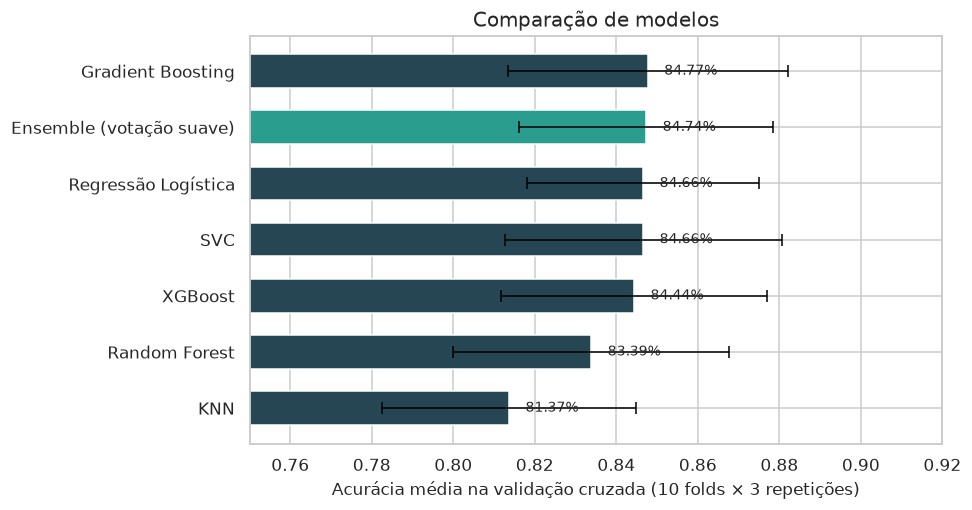

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ordem = resultados.sort_values("cv_media")
cores_bar = [COR_SURV if m == melhor else COR_ACCENT for m in ordem["modelo"]]
ax.barh(ordem["modelo"], ordem["cv_media"], color=cores_bar, height=0.6)
ax.errorbar(
    ordem["cv_media"],
    ordem["modelo"],
    xerr=ordem["cv_desvio"],
    fmt="none",
    ecolor="black",
    capsize=4,
    lw=1,
)
ax.set_xlim(0.75, 0.92)
ax.set_xlabel("Acurácia média na validação cruzada (10 folds × 3 repetições)")
ax.set_title("Comparação de modelos")
for y_pos, (_, row) in enumerate(ordem.iterrows()):
    ax.text(
        row["cv_media"] + 0.004,
        y_pos,
        f"{row['cv_media']:.2%}",
        va="center",
        fontsize=9,
    )
fig.tight_layout()
plt.show()


## 5. Modelo final, importância dos atributos e submissão

O modelo escolhido na validação cruzada é retreinado em **todo** o conjunto de treino e gera previsões para os 418 passageiros do teste. O arquivo segue o formato exigido pelo Kaggle: `PassengerId,Survived`. A versão anterior da submissão foi conservada em `submissions/submission_v1.csv`.


In [10]:
submission = fit_best_and_predict(
    X, y, test, melhor, passenger_pool=pool, cv_results=resultados
)
SUBMISSION_PATH.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(SUBMISSION_PATH, index=False)

print(f"Arquivo: {SUBMISSION_PATH}")
print(f"Linhas: {len(submission)} (esperado: 418)")
print(f"IDs: {submission['PassengerId'].min()}–{submission['PassengerId'].max()}")
print(
    "Previsões: "
    f"{int((submission['Survived'] == 1).sum())} sobreviventes "
    f"({submission['Survived'].mean():.1%}) e "
    f"{int((submission['Survived'] == 0).sum())} não sobreviventes"
)
display(submission.head())

assert len(submission) == 418
assert list(submission.columns) == ["PassengerId", "Survived"]
assert submission["Survived"].isin([0, 1]).all()
assert submission["PassengerId"].is_unique


Arquivo: /workspace/kaggle-titanic/submissions/submission.csv
Linhas: 418 (esperado: 418)
IDs: 892–1309
Previsões: 153 sobreviventes (36.6%) e 265 não sobreviventes


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


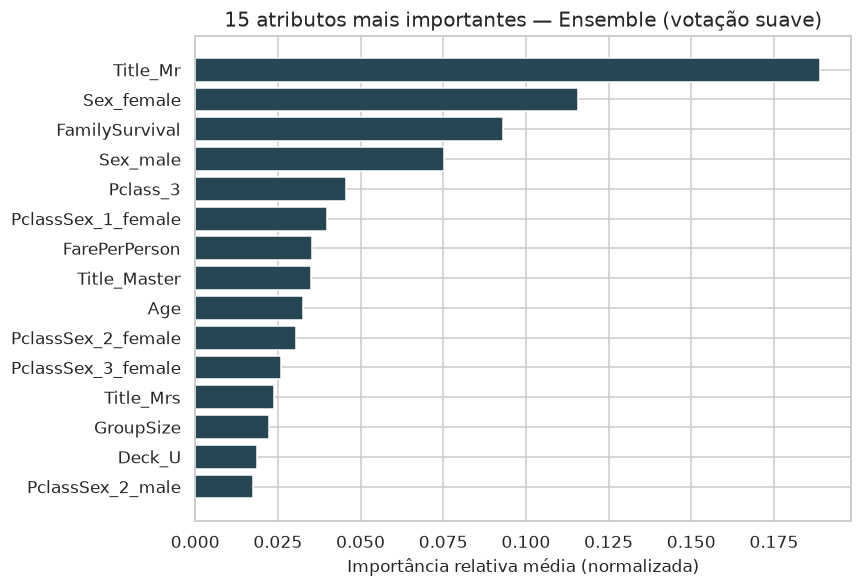

,atributo,importancia
0,Title_Mr,0.188966
1,Sex_female,0.115616
2,FamilySurvival,0.093084
3,Sex_male,0.075234
4,Pclass_3,0.045744
5,PclassSex_1_female,0.039992
6,FarePerPerson,0.035240
7,Title_Master,0.034971
8,Age,0.032664
9,PclassSex_2_female,0.030486


In [11]:
pipe_final, imp = collect_top_features(
    X, y, test, melhor, passenger_pool=pool, cv_results=resultados, top=15
)
if imp.empty:
    print(f"{melhor} não expõe importâncias ou coeficientes; gráfico omitido.")
else:
    plot = imp.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.barh(plot["atributo"], plot["importancia"], color=COR_ACCENT)
    ax.set_xlabel("Importância relativa média (normalizada)")
    ax.set_title(f"15 atributos mais importantes — {melhor}")
    fig.tight_layout()
    plt.show()
    display(imp)


## 6. Conclusões e próximos passos

- Sexo, classe e título continuam carregando a maior parte do sinal. A novidade que mais agrega é o **`FamilySurvival`**: saber se o resto da família ou do ticket sobreviveu, calculado em leave-one-out e só com rótulos do fold de treino. A interação `PclassSex`, a tarifa por pessoa e o tamanho do grupo também entram entre os atributos mais importantes.
- O ensemble de votação suave (Gradient Boosting, regressão logística, SVC e XGBoost) empatou na prática com o Gradient Boosting isolado e foi escolhido por ter desvio um pouco menor. O KNN ficou atrás e ficou de fora da votação. Modelos rasos e regularizados são o desenho certo para 891 linhas — modelos fundos decoram o treino.
- **Sobre a leaderboard.** O topo do ranking do Titanic (100%) vem de rótulos vazados, não de um modelo melhor. Uma solução legítima séria fica em torno de **0,80–0,82** no ranking público. A acurácia da CV (cerca de 85%) costuma ser um pouco otimista em relação a esse número: o teste oculto é pequeno e ruidoso. **Não afirmamos uma nota na leaderboard** — ela só existe depois do envio. Perseguir o ranking público é a forma mais rápida de superajustar.
- **Nota de portfólio:** este projeto mostra o fluxo de uma competição de classificação (exploração, pipeline reproduzível, validação honesta, submissão). Ele **não** basta, sozinho, para evidenciar experiência com redes neurais profundas. Para isso, o próximo passo natural é uma competição de imagem ou texto (ou uma Playground Series mais recente, com ranking de verdade).

Para enviar a submissão, faça o upload de `submissions/submission.csv` na [página da competição](https://www.kaggle.com/competitions/titanic/submit).
